# SpinPulse

A short hands-on tutorial on SpinPulse, adapted from the official
[Basic Usage tutorial](https://quobly-sw.github.io/SpinPulse/customapi/tutorials/BasicUsage.html). Other more [advanced tutorials](https://quobly-sw.github.io/SpinPulse/customapi/tutorials/index_simple.html) are available online.

To get a deeper understanding on SpinPulse, please refer to the [original paper](https://arxiv.org/abs/2601.10435).

SpinPulse documentation is available [here](https://quobly-sw.github.io/SpinPulse/autoapi/spin_pulse/index.html).
## Environment setup

If it's not already done, create a dedicated conda environment from a terminal:

```bash
conda create -n spinpulse -c conda-forge python=3.12 numpy scipy matplotlib jupyterlab pip -y \
  && conda run -n spinpulse pip install spin-pulse pylatexenc
```

Then select the `spinpulse` kernel in JupyterLab.

## What SpinPulse is

SpinPulse is an open-source Python package developed by Quobly for simulating
silicon spin-qubit quantum computers.

- **It works at the pulse level.** A pulse is the actual control signal sent to the hardware. Instead of applying ideal unitaries, SpinPulse simulates the physical dynamics of the spin qubits under those signals: each native gate is realised by a shaped pulse of finite duration, and the resulting evolution is integrated numerically.
- **It models non-Markovian noise.** Spin qubits are dominated by slowly drifting classical quantities. These fluctuate on timescales much longer than a single gate, so the environment has memory, something that a Kraus channel applied gate by gate cannot reproduce.

## The SpinPulse pipeline can be described as follow:

1.  **Gate transpilation**: Transpilation of a qiskit circuit to the SpinPulse native gate set
   (`RX`, `RY`, `RZ`, `RZZ`).
2. **Pulse transpilation**: Compiling that circuit into a pulse sequence.
3. **Numerical integration**: Calculation the evolution operator associated with each pulse sequence.
4. **Noisy Environement**: Running the simulation in a noisy environment with configurable hardware parameters.


<div style="background-color: white; style="max-width: 100%; height: auto;"">

![Fig1](https://quobly-sw.github.io/SpinPulse/_images/global_fig.png)

</div>


In [1]:
import qiskit
from qiskit.quantum_info import Operator, average_gate_fidelity

from spin_pulse import PulseCircuit, DynamicalDecoupling
from spin_pulse.environment.noise import NoiseType
from spin_pulse.environment.experimental_environment import ExperimentalEnvironment
from spin_pulse.transpilation.hardware_specs import HardwareSpecs, Shape

## Hardware specifications

[`HardwareSpecs`](https://quobly-sw.github.io/SpinPulse/autoapi/spin_pulse/transpilation/hardware_specs/index.html#spin_pulse.transpilation.hardware_specs.HardwareSpecs) describes the QPU we want to simulate. 

We can specify:
- `num_qubits` — number of qubits
- `B_field` — **maximum** amplitude of the drive field $B_i(t)$, used for $R_X$ / $R_Y$ rotations
- `delta` — **maximum** energy difference between two qubits $\delta\omega_i(t)$, used for $R_Z$ rotations
- `J_coupling` — **maximum** exchange coupling $J_{i,j}(t)$ between neighbouring qubits, used for $R_{ZZ}$
- `rotation_shape` — the pulse shape (`GAUSSIAN` or `SQUARE`)
- `ramp_duration` — ramp duration, for square pulses only
- `coeff_duration` — duration coefficient, for Gaussian pulses only

`optim` is the optimization level of the underlying Qiskit transpiler.

In [2]:
num_qubits = 3
B_field, delta, J_coupling = 0.5, 0.2, 0.01
ramp_duration = 5

hardware_specs = HardwareSpecs(
    num_qubits, B_field, delta, J_coupling, Shape.GAUSSIAN, ramp_duration, optim=0
)

## Qiskit Quantum Circuit

The circuits are described using Qiskit. 

As an example here, we create a simple Bell state on qubits 0 and 1, while qubit 2 stays idle. We will later see how noise affects an inactive qubit.

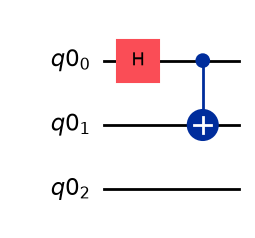

In [3]:
qreg = qiskit.QuantumRegister(num_qubits)
qc = qiskit.QuantumCircuit(qreg)

qc.h(0)
qc.cx(0, 1)
qc.draw("mpl")

## 1. Gate Transpilation

The `gate_transpile` method from the HardwareSpecs class converts our circuit to an ISA circuit that is composed of the native gates of the spin qubit platform ($R_{X}$, $R_{Y}$, $R_{Z}$ and $R_{ZZ}$).

This step is realized through pre-configured qiskit transpilers.

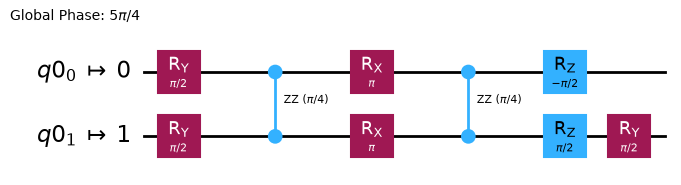

In [4]:
isa_qc = hardware_specs.gate_transpile(qc)
isa_qc.draw("mpl")

Both circuits are equivalent and describe the same unitary channel. Here is a sanity check comparing them. 

(The result is not exactly 1 because of floating-point rounding, not because of any physical difference.)

In [5]:
# the transpilation process might modify the ordering between physical and logical qubits
# the function from_circuit takes into account the layout of the transpiled circuit to ensure consistent ordering

fid_isa = average_gate_fidelity(Operator.from_circuit(qc), Operator.from_circuit(isa_qc))
print(f"Fidelity circuit / ISA circuit: {fid_isa}")

Fidelity circuit / ISA circuit: 0.9999999999999996


## 2. Pulse Transpilation

`PulseCircuit.from_circuit` parametrizes the spin-model Hamiltonians and computes the pulse durations
needed to implement the $R_{X,Y,Z}$ and $R_{ZZ}$ rotations.

Idle times are inserted automatically to synchronize the qubits at each circuit layer.

In the plot: 
- red = single-qubit $R_X$/$R_Y$ gates (driven by an oscillating magnetic field)
- blue = the two-qubit Heisenberg ($J$-coupling) pulse, together with the $R_Z$ gates
  that set up the delta ($z$) plateau it requires

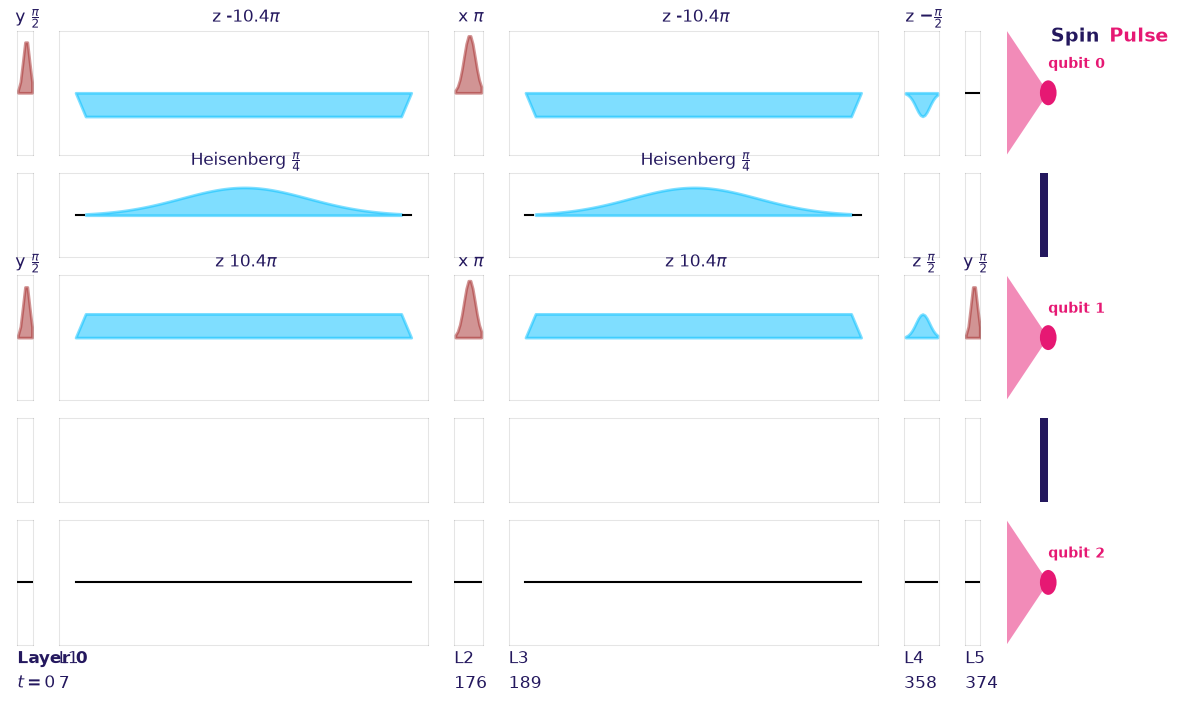

In [6]:
pulse_circuit = PulseCircuit.from_circuit(isa_qc, hardware_specs)
pulse_circuit.plot(hardware_specs=hardware_specs)

## 3. Numerical integration

The function `to_circuit()` integrates the pulses and returns a Qiskit `QuantumCircuit`, where gates are the unitary matrices actually implemented by the pulse sequence.

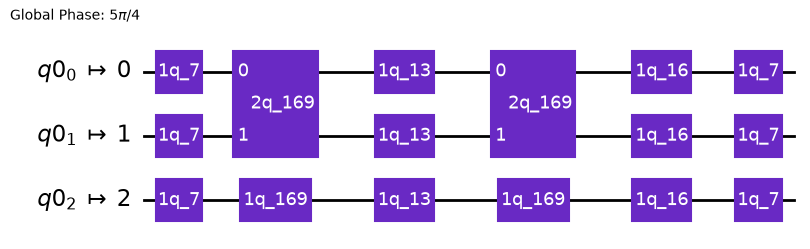

In [7]:
implemented_qc = pulse_circuit.to_circuit()
implemented_qc.draw("mpl", style="textbook")

The deviation from unity comes from small non-adiabatic contributions in the two-qubit gate.
The function `pulse_circuit.fidelity()` evaluates this metric directly from the pulse circuit.

In [8]:
fid_impl = average_gate_fidelity(
    Operator.from_circuit(implemented_qc), Operator.from_circuit(qc)
)
print(f"Fidelity implemented / ideal: {fid_impl:.12f}")
print(f"Via pulse_circuit.fidelity(): {pulse_circuit.fidelity():.12f}")

Fidelity implemented / ideal: 0.999999657095
Via pulse_circuit.fidelity(): 0.999999657095


## 4. Noisy Environement

`ExperimentalEnvironment` generates a noise time trace on each qubit: instead of applying an independent error to each gate, we draw a full trace and run the whole circuit on it, then average over many draws.

- the noise type is pink noise `NoiseType.PINK`, a 1/f noise coming from charge defects in the oxide, which is the dominant noise source in spin qubits
- `T2S` is the coherence time $T_2^*$, the timescale over which a qubit loses its phase under this slowly drifting noise
- `segment_duration` sets which frequency components are present in the trace.

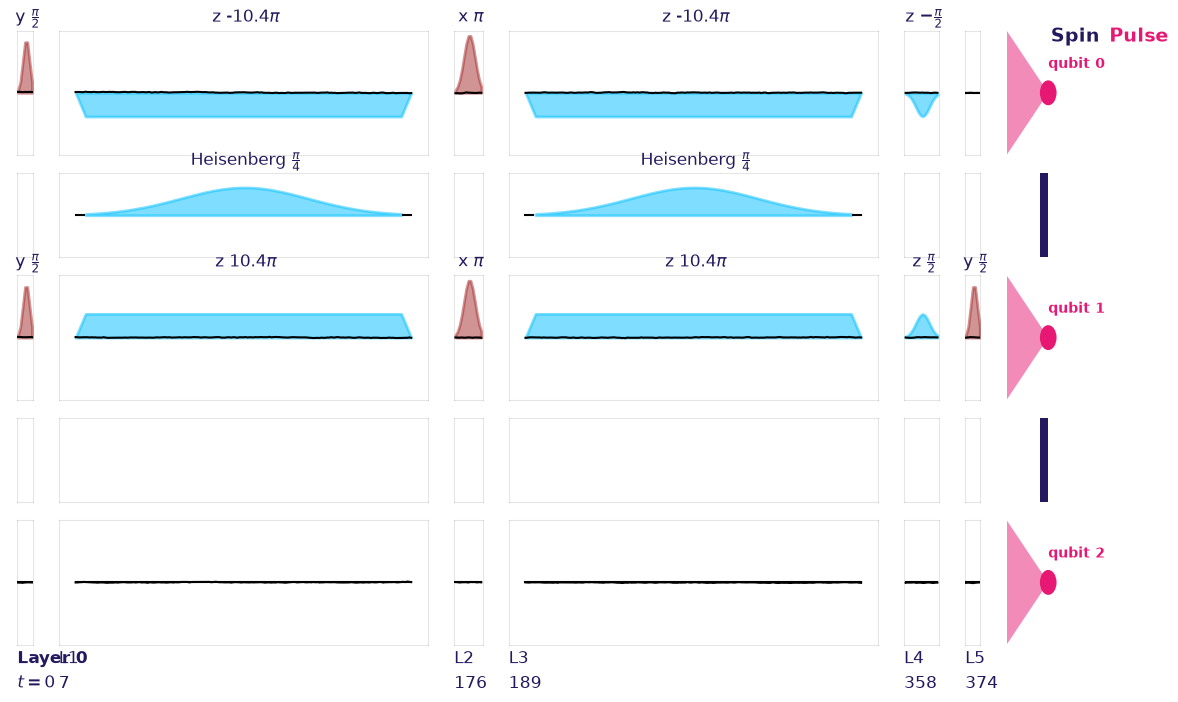

In [9]:
exp_env = ExperimentalEnvironment(
    hardware_specs=hardware_specs,
    noise_type=NoiseType.PINK,
    T2S=500,
    duration=2**15,
    segment_duration=2**15,
)

pulse_circuit_noise = PulseCircuit.from_circuit(isa_qc, hardware_specs, exp_env=exp_env)
pulse_circuit_noise.plot(hardware_specs)

In [10]:
fid_noise = pulse_circuit_noise.mean_fidelity(exp_env)
print(f"Mean fidelity with noise: {fid_noise:.6f}")

100%|██████████| 86/86 [00:00<00:00, 184.71it/s]

Mean fidelity with noise: 0.901487


## Square pulses

A single argument (`Shape.SQUARE`) switches the pulse shape and can be compared directly.

Fidelity (square, noiseless): 0.999955754886


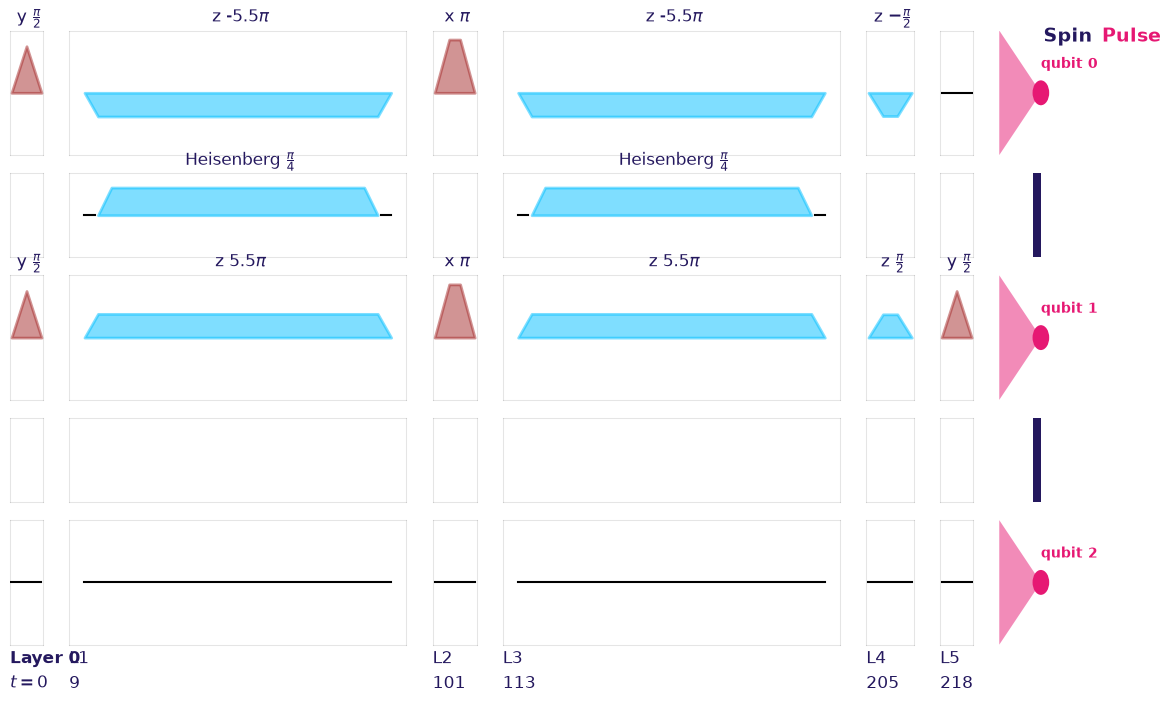

In [11]:
ramp_duration_square = 4
hardware_specs_square = HardwareSpecs(
    num_qubits, B_field, delta, J_coupling, Shape.SQUARE, ramp_duration_square
)

pulse_circuit_square = PulseCircuit.from_circuit(isa_qc, hardware_specs_square)
print(f"Fidelity (square, noiseless): {pulse_circuit_square.fidelity():.12f}")
pulse_circuit_square.plot(hardware_specs_square)

## Dynamical decoupling

The `dynamical_decoupling` argument replaces idle sequences with single-qubit rotations, protecting
the qubit from the low-frequency part of the noise (the high-frequency part still affects coherence).

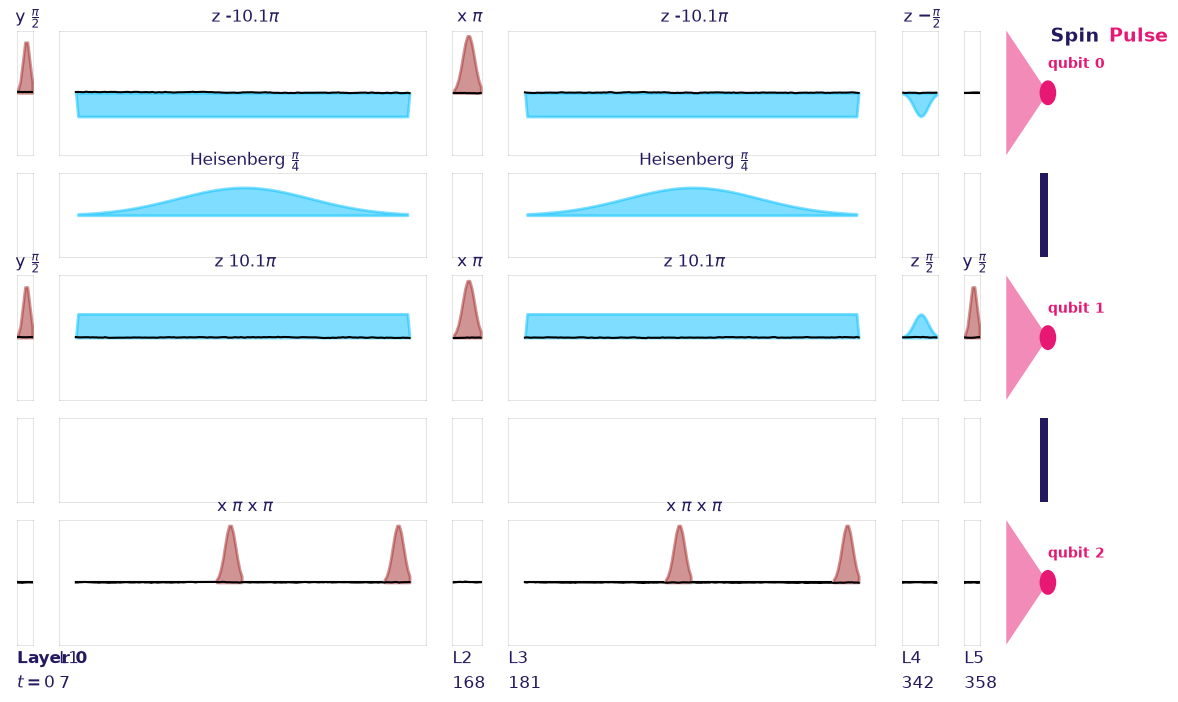

In [12]:
hardware_specs_dd = HardwareSpecs(
    num_qubits,
    B_field,
    delta,
    J_coupling,
    Shape.GAUSSIAN,
    dynamical_decoupling=DynamicalDecoupling.SPIN_ECHO,
)

pulse_circuit_dd = PulseCircuit.from_circuit(isa_qc, hardware_specs_dd, exp_env=exp_env)
pulse_circuit_dd.plot(hardware_specs_dd)

In [13]:
print(f"Mean fidelity without DD: {pulse_circuit_noise.mean_fidelity(exp_env):.6f}")
print(f"Mean fidelity with DD:    {pulse_circuit_dd.mean_fidelity(exp_env):.6f}")

100%|██████████| 86/86 [00:00<00:00, 181.98it/s]


Mean fidelity without DD: 0.901487


100%|██████████| 89/89 [00:00<00:00, 181.46it/s]

Mean fidelity with DD:    0.970895


# qBraid

Instead of running SpinPulse locally, you can run your quantum circuit on [Alloy Forge](https://account.qbraid.com/devices/quobly/qbraid/alloy-forge), Quobly's spin qubit simulator.
It is available for free on qBraid, you just need to create a qBraid account.

qBraid is a cloud service (like Google Colab) where you can run notebooks on different machine configurations: CPU, GPU, etc. The specificity of qBraid is that it is oriented for quantum computing, and allows you to run your code on real quantum hardware or on quantum simulators. They offer multiple backends and they also host Alloy Forge, a simulator of Quobly's future Pioneer quantum computer.

You also get 100h of free CPU computation time per month (be careful: using an 8-core notebook means you consume 8 computation hours per real hour!) and can run your code directly on qBraid.
If you want to use a qBraid QPU or quantum simulator while running your code locally, you will need to create an [API key](https://account.qbraid.com/account/api-keys).

In [14]:
%pip install 'qbraid[visualization]' qiskit

Note: you may need to restart the kernel to use updated packages.


In [ ]:
from qbraid import QbraidProvider

# if you are running locally on your computer, you need to add you api key as parameter :
# provider = QbraidProvider(api_key="YOU_API_KEY")

provider = QbraidProvider()

device = provider.get_device("qbraid:quobly:sim:alloy-forge")

## Qiskit Quantum Circuit

As before, we use Qiskit to create our quantum circuit. We create the same bell state circuit as before.

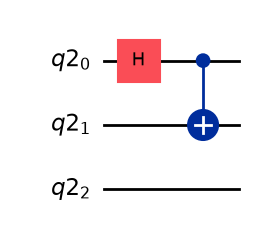

In [17]:
qreg = qiskit.QuantumRegister(num_qubits)
circ = qiskit.QuantumCircuit(qreg)

circ.h(0)
circ.cx(0, 1)
circ.draw("mpl")

# Run without noise

In [18]:
ideal_job = device.run(qc, shots=1000, runtime_options={"noise": False, "seed": 1234})
ideal_counts = ideal_job.result().data.get_counts()

ideal_counts

{'000': 484, '011': 516}

# Run it with the Pioneer noise model

Use `noise = True` in order to have Pioneer noise simulation

In [19]:
noisy_job = device.run(qc, shots=1000, runtime_options={"noise": True, "seed": 1234})
noisy_counts = noisy_job.result().data.get_counts()

noisy_counts

{'000': 483, '001': 1, '010': 3, '011': 513}

More tutorials on qBraid [here](https://github.com/qBraid/qbraid-lab-demo/blob/main/qBraid-Runtime/quobly_alloy_forge_quickstart.ipynb).